# 05 - Baseline model: logistic regression

**Day 4 (Ali):** build the first xG model, measure how good it is, and **interpret the coefficients**.

| Model | Features |
|---|---|
| Baseline | every shot gets the average goal rate of the train set |
| **A** | `distance`, `angle`, `header`, `counter_attack` |
| **B** | A + `score_diff` (score at the moment of the shot) |

Code: `src/model.py` (model) and `src/evaluate.py` (metrics, by Hasan).
Data: `train.csv` / `test.csv` from `src/split.py` (open-play shots, split by match).

**Rule we follow:** all model choices are made with cross-validation on the **train** set.
The **test** set is used only once, at the end (section 9).

Run the cells from top to bottom with the **`.venv`** kernel.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor

sys.path.append(str(Path("..").resolve() / "src"))
from model import (FEATURES_A, FEATURES_B, coefficient_table, cross_validate, cross_validate_baseline,
                   design_matrix, fit_logit, load_train_test, predict_xg, standardize)
from evaluate import baseline_prob, calibration_table, compare_models, evaluate, plot_calibration
from features import distance_to_goal, shot_angle, to_meters
from eda_utils import draw_half_pitch

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    """Save a figure into reports/figures."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

## 2. How logistic regression works
A normal linear regression can predict any number, but a probability must stay between 0 and 1.
Logistic regression solves this in two steps:

1. A **linear score** from the features: $z = b_0 + b_1 \cdot \text{distance} + b_2 \cdot \text{angle} + \dots$
2. The **sigmoid** squeezes the score into a probability: $xG = \dfrac{1}{1 + e^{-z}}$

The score $z$ is the **log-odds** of a goal. That gives the coefficients a clean meaning:

- **odds** = P(goal) / P(no goal). A 20% chance is odds of 0.25 ("1 goal for every 4 misses").
- **odds ratio** = $e^{b}$: when a feature goes up by one unit, the odds are **multiplied** by $e^{b}$.
  - odds ratio 0.9: odds drop by 10% per unit
  - odds ratio 2.0: odds double
  - odds ratio 1.0: no effect

The fit chooses the coefficients that make the observed goals most likely (maximum likelihood).

## 3. Data

In [2]:
train, test = load_train_test()

summary = pd.DataFrame({
    "matches": [train["matchId"].nunique(), test["matchId"].nunique()],
    "shots": [len(train), len(test)],
    "goals": [train["is_goal"].sum(), test["is_goal"].sum()],
    "goal_rate": [train["is_goal"].mean(), test["is_goal"].mean()],
}, index=["train", "test"])
display(summary.round(3))

# Safety checks: open play only, and no match on both sides
assert (train["shot_type"] == "shot").all() and (test["shot_type"] == "shot").all()
assert not set(train["matchId"]) & set(test["matchId"])

train[FEATURES_B].describe().round(2)

,matches,shots,goals,goal_rate
train,304,6755,738,0.109
test,76,1696,176,0.104


,distance,angle,score_diff
count,6755.00,6755.00,6755.00
mean,18.26,0.42,0.03
std,8.04,0.26,1.22
min,1.25,0.05,-5.00
25%,12.15,0.26,-1.00
50%,16.85,0.34,0.00
75%,24.59,0.51,1.00
max,67.66,2.57,6.00


All features are known **at the moment of the shot** (no leakage). `header` and `counter_attack`
are True/False and enter the model as 1/0.

## 4. Baseline
The simplest possible "model": every shot gets the train goal rate (10.9%).
It knows nothing about the shot, so its AUC is 0.5 (a coin flip at ranking shots).
Any real model must beat it.

In [3]:
cv_baseline = cross_validate_baseline(train)
cv_baseline[["log_loss", "brier", "roc_auc"]].agg(["mean", "std"]).round(4)

,log_loss,brier,roc_auc
mean,0.3451,0.0973,0.5
std,0.0135,0.0050,0.0


## 5. Model A
### 5.1 Fit and coefficient table

In [4]:
model_a = fit_logit(train, FEATURES_A)
coef_a = coefficient_table(model_a)
coef_a.round(3)

,coef,std_err,ci_low,ci_high,p_value,odds_ratio,or_low,or_high
const,-0.977,0.259,-1.484,-0.470,0.0,0.377,0.227,0.625
distance,-0.112,0.011,-0.134,-0.090,0.0,0.894,0.874,0.914
angle,1.385,0.211,0.971,1.799,0.0,3.994,2.639,6.044
header,-0.840,0.114,-1.063,-0.616,0.0,0.432,0.345,0.540
counter_attack,0.817,0.152,0.520,1.115,0.0,2.264,1.682,3.049


How to read the table:
- `coef`: change in log-odds for one unit (1 m, 1 radian, or 0 -> 1)
- `ci_low` / `ci_high`: 95% confidence interval of the coefficient
- `p_value`: how surprising the coefficient would be if the true effect were zero (small = clear effect)
- `odds_ratio` = `exp(coef)`, with its 95% interval in `or_low` / `or_high`

All four features have p-values far below 0.001 and none of the intervals crosses zero,
so every feature has a clear effect.

### 5.2 Check: scikit-learn gives the same model
`statsmodels` and scikit-learn's `LogisticRegression` (without a penalty) solve the same problem.
We fit both and compare the coefficients as a sanity check.

In [5]:
sk_model = LogisticRegression(C=1e9, max_iter=5000)   # C very large = practically no penalty
sk_model.fit(train[FEATURES_A].astype(float), train["is_goal"])
sk_coefs = np.r_[sk_model.intercept_, sk_model.coef_[0]]

check = pd.DataFrame({"statsmodels": model_a.params, "scikit-learn": sk_coefs})
check["difference"] = (check["statsmodels"] - check["scikit-learn"]).abs()
check.round(4)

,statsmodels,scikit-learn,difference
const,-0.9767,-0.9766,0.0001
distance,-0.1123,-0.1123,0.0000
angle,1.3848,1.3847,0.0001
header,-0.8398,-0.8396,0.0003
counter_attack,0.8172,0.8174,0.0002


## 6. Interpreting the coefficients
"Per radian" is hard to imagine, so we convert every effect to a football-sized unit:
**+5 m** of distance, **+10 degrees** of angle, and yes vs no for header and counter attack.
For a change of `k` units, the odds ratio is $e^{k \cdot b}$.

In [6]:
def readable_odds_ratios(coef_table, units):
    """Odds ratio and 95% interval for a change of `units[feature]` in each feature."""
    rows = []
    for feature, (step, label) in units.items():
        c = coef_table.loc[feature]
        rows.append({
            "feature": feature,
            "change": label,
            "odds_ratio": np.exp(step * c["coef"]),
            "or_low": np.exp(step * c["ci_low"]),
            "or_high": np.exp(step * c["ci_high"]),
        })
    out = pd.DataFrame(rows).set_index("feature")
    out["effect_on_odds"] = ((out["odds_ratio"] - 1) * 100).round(1).astype(str) + "%"
    return out


UNITS = {
    "distance": (5, "+5 m"),
    "angle": (np.radians(10), "+10 deg"),
    "header": (1, "header vs foot"),
    "counter_attack": (1, "counter vs other"),
    "score_diff": (1, "+1 goal ahead"),
}
readable_a = readable_odds_ratios(coef_a, {k: v for k, v in UNITS.items() if k in FEATURES_A})
readable_a.round(3)

,change,odds_ratio,or_low,or_high,effect_on_odds
feature,,,,,
distance,+5 m,0.570,0.511,0.636,-43.0%
angle,+10 deg,1.273,1.185,1.369,27.3%
header,header vs foot,0.432,0.345,0.540,-56.8%
counter_attack,counter vs other,2.264,1.682,3.049,126.4%


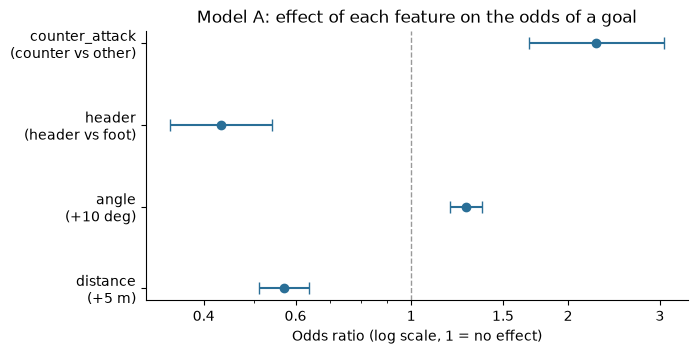

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = [f"{f}\n({row['change']})" for f, row in readable_a.iterrows()]
y_pos = np.arange(len(readable_a))
ax.errorbar(readable_a["odds_ratio"], y_pos,
            xerr=[readable_a["odds_ratio"] - readable_a["or_low"], readable_a["or_high"] - readable_a["odds_ratio"]],
            fmt="o", color="#2a6f97", capsize=4)
ax.axvline(1, color="#999999", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 1, 1.5, 2, 3], ["0.4", "0.6", "1", "1.5", "2", "3"])
ax.set_yticks(y_pos, labels)
ax.set_xlabel("Odds ratio (log scale, 1 = no effect)")
ax.set_title("Model A: effect of each feature on the odds of a goal")
save(fig, "18_odds_ratios.png")

**Interpretation (model A):**
- **Distance:** every extra **5 m multiplies the odds by about 0.57** (-43%). Per metre it is 0.89 (-11%).
  This is the strongest effect in the model.
- **Angle:** every extra **10 degrees multiplies the odds by about 1.27** (+27%), *on top of* distance.
- **Header:** at the same distance and angle, a header has **0.43x** the odds of a foot shot (-57%).
- **Counter attack:** a shot from a counter attack has **2.3x** the odds (+126%) of the same shot
  in another situation. A plausible reason is a defence that is not yet organised.

### 6.1 Example shots
Probabilities are easier to feel than odds. Same model, a few typical shots:

In [8]:
def central_shot(distance_m, header=0, counter=0):
    """A shot straight in front of goal from `distance_m` metres."""
    x_m, y_m = 105 - distance_m, 34
    return {"distance": distance_m, "angle": float(shot_angle(x_m, y_m)),
            "header": header, "counter_attack": counter}


examples = pd.DataFrame([
    central_shot(6), central_shot(6, header=1),
    central_shot(11), central_shot(11, header=1), central_shot(11, counter=1),
    central_shot(20), central_shot(30),
], index=["6 m foot", "6 m header", "11 m foot", "11 m header", "11 m foot, counter",
          "20 m foot", "30 m foot"])
examples["angle_deg"] = np.degrees(examples["angle"]).round(1)
examples["xG"] = predict_xg(model_a, examples, FEATURES_A).round(3)
examples[["distance", "angle_deg", "header", "counter_attack", "xG"]]

,distance,angle_deg,header,counter_attack,xG
6 m foot,6,62.8,0,0,0.467
6 m header,6,62.8,1,0,0.274
11 m foot,11,36.8,0,0,0.210
11 m header,11,36.8,1,0,0.103
"11 m foot, counter",11,36.8,0,1,0.376
20 m foot,20,20.7,0,0,0.062
30 m foot,30,13.9,0,0,0.018


### 6.2 Why is the header coefficient negative?
In notebook 02, headers scored **more** often than foot shots (13.5% vs about 10%).
The model says the opposite. Both are true, and this is the most important lesson of Day 4:

In [9]:
header_only = fit_logit(train, ["header"])
print("Raw goal rate  - header: {:.1%} | foot: {:.1%}".format(
    train.loc[train["header"], "is_goal"].mean(), train.loc[~train["header"], "is_goal"].mean()))
print("Median distance - header: {:.1f} m | foot: {:.1f} m".format(
    train.loc[train["header"], "distance"].median(), train.loc[~train["header"], "distance"].median()))
print(f"Header coefficient alone:             {header_only.params['header']:+.3f}")
print(f"Header coefficient with distance etc.: {model_a.params['header']:+.3f}")

Raw goal rate  - header: 13.7% | foot: 10.4%
Median distance - header: 10.4 m | foot: 18.8 m
Header coefficient alone:             +0.314
Header coefficient with distance etc.: -0.840


**Interpretation:** alone, `header` is **positive** because headers happen close to goal.
Once the model knows the distance and angle, the remaining effect of heading is **negative**:
a header is harder to place than a kick from the same spot. Distance was a **confounder**.
This matches Hasan's finding in notebook 04 (0-8 m: headers 27% vs feet 46%).

## 7. Distance and angle: do we need both?
The two features are strongly related (Spearman -0.89 in notebook 03). We check three things:
1. Variance inflation factor (VIF): how much each feature is explained by the others.
2. Models with distance only, angle only and both.
3. Standardised coefficients: which feature matters more per "typical" change.

In [10]:
X_a = design_matrix(train, FEATURES_A)
vif = pd.Series([variance_inflation_factor(X_a.values, i) for i in range(1, X_a.shape[1])],
                index=FEATURES_A, name="VIF")
vif.round(2)

distance          2.34
angle             2.32
header            1.26
counter_attack    1.01
Name: VIF, dtype: float64

A VIF above 5-10 is usually a warning sign. Ours are about 2.3, so the overlap is
**moderate**: the coefficients are stable and can be interpreted.

In [11]:
geometry_sets = {
    "distance only": ["distance"],
    "angle only": ["angle"],
    "distance + angle": ["distance", "angle"],
}
rows = {}
for name, feats in geometry_sets.items():
    cv = cross_validate(train, feats)
    fitted = fit_logit(train, feats)
    rows[name] = {"cv_log_loss": cv["log_loss"].mean(), "cv_auc": cv["roc_auc"].mean(),
                  **{f"coef_{f}": fitted.params[f] for f in feats}}
pd.DataFrame(rows).T.round(4)

,cv_log_loss,cv_auc,coef_distance,coef_angle
distance only,0.3018,0.7581,-0.1480,NaN
angle only,0.3063,0.7521,NaN,2.8411
distance + angle,0.2993,0.7610,-0.0968,1.1882


In [12]:
train_s, _, std = standardize(train, test, ["distance", "angle"])
model_a_std = fit_logit(train_s, FEATURES_A)
print("Standard deviation in train:", std.round(3).to_dict(), "(angle in radians)")
coefficient_table(model_a_std)[["coef", "ci_low", "ci_high"]].round(3)

Standard deviation in train: {'distance': 8.044, 'angle': 0.259} (angle in radians)


,coef,ci_low,ci_high
const,-2.441,-2.556,-2.326
distance,-0.904,-1.080,-0.727
angle,0.359,0.252,0.467
header,-0.840,-1.063,-0.616
counter_attack,0.817,0.520,1.115


**Interpretation:**
- Together, distance and angle beat either one alone (lower log loss), so both carry information.
- Both coefficients keep the expected sign when used together (distance negative, angle positive).
- **Standardised:** one standard deviation of distance (about 8 m) moves the log-odds by about -0.90,
  one standard deviation of angle (about 15 deg) by about +0.36. **Distance is the main driver**;
  angle refines it (central vs wide at the same distance).

## 8. Choosing the model with cross-validation (train set only)
We compare the models on 5 folds of the train set, split by match (`GroupKFold`).
Because all models use **the same folds**, we can compare them fold by fold, which removes
the noise of "easy" and "hard" folds.

We also test `log(distance)` (model A_log): the goal rate falls quickly close to goal and then
flattens, and a log might follow that curve better.

In [13]:
train["log_distance"] = np.log(train["distance"])
test["log_distance"] = np.log(test["distance"])

candidates = {
    "A": FEATURES_A,
    "B": FEATURES_B,
    "A_log": ["log_distance", "angle", "header", "counter_attack"],
}
cv_results = {"baseline": cv_baseline}
cv_results.update({name: cross_validate(train, feats) for name, feats in candidates.items()})

cv_summary = pd.DataFrame({
    name: {"log_loss": r["log_loss"].mean(), "log_loss_sd": r["log_loss"].std(),
           "brier": r["brier"].mean(), "roc_auc": r["roc_auc"].mean()}
    for name, r in cv_results.items()
}).T
cv_summary.round(4)

,log_loss,log_loss_sd,brier,roc_auc
baseline,0.3451,0.0135,0.0973,0.5000
A,0.2928,0.0081,0.0845,0.7782
B,0.2922,0.0080,0.0843,0.7788
A_log,0.2936,0.0075,0.0848,0.7754


In [14]:
paired = pd.DataFrame({
    "B - A": cv_results["B"]["log_loss"] - cv_results["A"]["log_loss"],
    "A_log - A": cv_results["A_log"]["log_loss"] - cv_results["A"]["log_loss"],
})
print("Negative = better than model A")
display(paired.round(4))
print("Folds where B beats A:     ", (paired["B - A"] < 0).sum(), "of 5")
print("Folds where A_log beats A: ", (paired["A_log - A"] < 0).sum(), "of 5")

model_b = fit_logit(train, FEATURES_B)
lr_stat = 2 * (model_b.llf - model_a.llf)
print(f"\nLikelihood-ratio test B vs A: statistic {lr_stat:.2f} (above 3.84 = significant at 5%)")
print(f"score_diff coefficient: {model_b.params['score_diff']:+.3f}, p = {model_b.pvalues['score_diff']:.4f}")

Negative = better than model A


,B - A,A_log - A
fold,,
1,-0.0008,0.0027
2,-0.0009,0.0016
3,0.0006,0.0002
4,-0.0009,-0.0004
5,-0.0007,-0.0003


Folds where B beats A:      4 of 5
Folds where A_log beats A:  2 of 5

Likelihood-ratio test B vs A: statistic 7.78 (above 3.84 = significant at 5%)
score_diff coefficient: +0.096, p = 0.0053


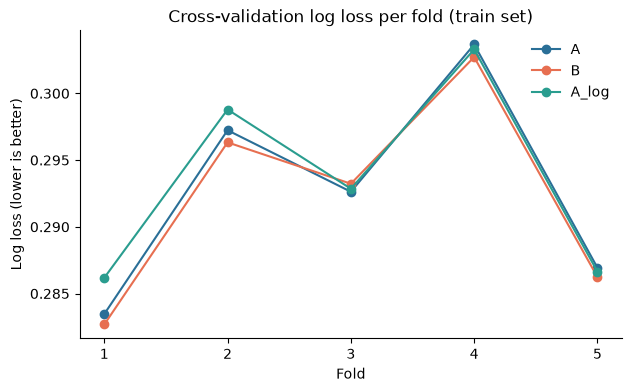

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, color in [("A", "#2a6f97"), ("B", "#e76f51"), ("A_log", "#2a9d8f")]:
    ax.plot(cv_results[name].index, cv_results[name]["log_loss"], marker="o", label=name, color=color)
ax.set_xlabel("Fold")
ax.set_ylabel("Log loss (lower is better)")
ax.set_xticks(range(1, 6))
ax.set_title("Cross-validation log loss per fold (train set)")
ax.legend(frameon=False)
save(fig, "19_cv_log_loss.png")

**Interpretation:**
- **A vs baseline:** log loss drops from about 0.345 to 0.293 and AUC rises from 0.50 to about 0.78 (0.80 on the test set).
  The model is far better than guessing the average.
- **B vs A:** adding `score_diff` helps in **4 of 5 folds**, but only by about **0.0005** log loss.
  The likelihood-ratio test says the effect is real (statistic 7.8, p = 0.005): each goal of lead
  multiplies the odds by about **1.10**. Real, but small.
- **A_log vs A:** `log(distance)` is **worse in 3 of 5 folds** and slightly worse on average. With it,
  the angle coefficient also stops being significant (the log curve takes over what angle did).
  **We keep plain distance.**

**Which model is "the" baseline?** We keep **model A** as the main baseline and **B** as an experiment.
Reason: xG is meant to measure *how good a chance is*. If the score is in the model, the same chance
gets a higher xG when the team is winning. For the player and team analysis (Days 6-7) that would mix
chance quality with the match situation. This is a recommendation to discuss with Hasan.

## 9. Final check on the test set (used once)

In [16]:
xg_a = predict_xg(model_a, test, FEATURES_A)
xg_b = predict_xg(model_b, test, FEATURES_B)
xg_base = baseline_prob(train["is_goal"], len(test))

test_results = compare_models({
    "baseline": evaluate(test["is_goal"], xg_base),
    "logit_A": evaluate(test["is_goal"], xg_a),
    "logit_B": evaluate(test["is_goal"], xg_b),
})
test_results.round(4)

,shots,goals,xg,xg_per_goal,log_loss,brier,roc_auc
baseline,1696.0,176.0,185.2921,1.0528,0.3335,0.0930,0.5000
logit_A,1696.0,176.0,183.3446,1.0417,0.2753,0.0792,0.7982
logit_B,1696.0,176.0,182.0960,1.0346,0.2733,0.0788,0.8044


The test results agree with cross-validation: model A has log loss **0.275** and AUC **0.80**
(Hasan's quick check gave the same), and B is slightly better (0.273 / 0.80).
The total xG is within about 4% of the real number of goals (183 xG vs 176 goals).

### 9.1 Calibration
Shots are put into 10 groups of equal size by predicted xG. For each group we compare
the **mean predicted xG** with the **real goal rate**. A perfect model lies on the diagonal.

,shots,mean_xg,goal_rate
0,170,0.014,0.018
1,170,0.023,0.018
2,169,0.033,0.036
3,170,0.048,0.029
4,170,0.065,0.024
5,170,0.084,0.059
6,170,0.107,0.124
7,168,0.139,0.137
8,169,0.186,0.225
9,170,0.382,0.371


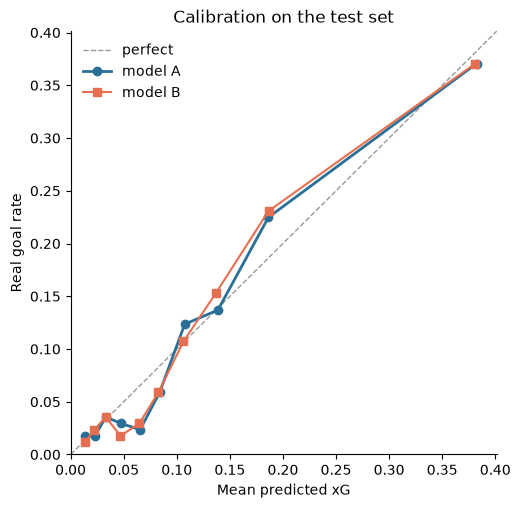

In [17]:
cal_a = calibration_table(test["is_goal"], xg_a)
cal_b = calibration_table(test["is_goal"], xg_b)
display(cal_a.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_calibration(ax, cal_a, label="model A", color="#2a6f97")
ax.plot(cal_b["mean_xg"], cal_b["goal_rate"], marker="s", color="#e76f51", linewidth=1.5, label="model B")
ax.legend(frameon=False)
ax.set_title("Calibration on the test set")
save(fig, "20_calibration.png")

**Interpretation:** the points follow the diagonal well, especially for the best chances
(top group: 38% predicted vs 37% real). Between about 4% and 7% predicted the model is a little
**too high** (real rate 2-3%). Each group has only about 170 shots (5-10 goals), so part of this is
noise; the Day 5 models will show whether a more flexible model fixes it.

### 9.2 Long shots
Logistic regression assumes the log-odds fall in a straight line with distance. The real goal rate
flattens beyond about 23 m (notebook 03). Does the model miss many long-range goals?

In [18]:
for name, df, xg in [("train", train, predict_xg(model_a, train, FEATURES_A)), ("test", test, xg_a)]:
    far = df["distance"] >= 25
    print(f"{name}: shots from 25 m+ = {far.sum()}, goals = {df.loc[far, 'is_goal'].sum()}, xG = {xg[far].sum():.1f}")

train: shots from 25 m+ = 1613, goals = 38, xG = 34.2
test: shots from 25 m+ = 419, goals = 7, xG = 8.9


On train the model gives 34 xG for 38 goals from 25 m or further, on test 8.9 xG for 7 goals.
The errors go in both directions and are small, so **no systematic problem** with long shots.

## 10. What the model sees: an xG map
xG of a **foot shot, not from a counter attack**, from every point of the attacking half.

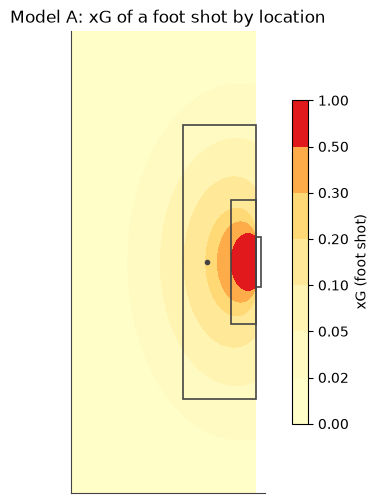

In [19]:
gx, gy = np.meshgrid(np.linspace(60, 100, 200), np.linspace(0, 100, 250))
grid_x_m, grid_y_m = to_meters(gx, gy)
grid = pd.DataFrame({
    "distance": distance_to_goal(grid_x_m, grid_y_m).ravel(),
    "angle": shot_angle(grid_x_m, grid_y_m).ravel(),
    "header": 0,
    "counter_attack": 0,
})
grid_xg = predict_xg(model_a, grid, FEATURES_A).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
cf = ax.contourf(gx, gy, grid_xg, levels=[0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1], cmap="YlOrRd", zorder=0)
draw_half_pitch(ax)
ax.set_xlim(60, 102)
fig.colorbar(cf, ax=ax, label="xG (foot shot)", shrink=0.7)
ax.set_title("Model A: xG of a foot shot by location")
save(fig, "21_xg_map.png")

## 11. Save predictions for Day 5
Test-set predictions of all three models, so the Day 5 models (Random Forest / XGBoost) can be
compared on exactly the same shots. The same file is created by `python src/model.py`.

In [20]:
predictions = test[["id", "matchId", "teamId", "playerId", "is_goal"]].copy()
predictions["xg_baseline"] = xg_base
predictions["xg_logit_A"] = xg_a
predictions["xg_logit_B"] = xg_b
predictions.to_csv("../data/processed/test_predictions.csv", index=False)
predictions.head()

,id,matchId,teamId,playerId,is_goal,xg_baseline,xg_logit_A,xg_logit_B
0,177959212,2499719,1609,25413,True,0.109252,0.129758,0.127760
1,177959247,2499719,1631,26150,False,0.109252,0.106753,0.096594
2,177959280,2499719,1631,14763,True,0.109252,0.399353,0.380821
3,177959289,2499719,1609,7868,False,0.109252,0.039685,0.039357
4,177959429,2499719,1609,7868,False,0.109252,0.018105,0.018096


## 12. Summary for the team
- **Model A** (`distance`, `angle`, `header`, `counter_attack`): test log loss **0.275**, Brier 0.079,
  AUC **0.80**, total xG within 4% of real goals. Far better than the baseline (0.334 / 0.50).
- **Effects (odds ratios):** +5 m = **x0.57**, +10 deg = **x1.27**, header = **x0.43**, counter attack = **x2.3**.
- **Header:** positive alone, negative once distance is in the model. Distance is a confounder.
- **Distance + angle:** related but both useful (VIF about 2.3); distance is the main driver.
- **Score (model B):** a real but small effect (+1 goal ahead = x1.10 odds, 4 of 5 folds better).
  Recommendation: keep A as the main xG model, because xG should measure chance quality only.
- `log(distance)` did not help; plain distance stays.
- Calibration is good overall, slightly too high for xG around 4-7%.
- **For Day 5 (Hasan):** `data/processed/test_predictions.csv` holds the baseline, A and B predictions
  for the test shots. New models can be added as extra columns and compared with `compare_models`.